<a href="https://colab.research.google.com/github/Rajshree-Hada/Problem-Set-1/blob/main/Ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

This household has two adults. They both work  annual income jobs and need vehicles to get to work. They spend most of their money right now on neccesities like rent, transportation, and grocieries.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [5]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Rent",               "Price_2019": 1419, "Price_2024": 1850, "weight": 0.43},
    {"Item": "Groceries",          "Price_2019": 660,  "Price_2024": 850,  "weight": 0.20},
    {"Item": "Car payments",       "Price_2019": 462,  "Price_2024": 620,  "weight": 0.14},
    {"Item": "Gasoline",           "Price_2019": 165,  "Price_2024": 210,  "weight": 0.05},
    {"Item": "Utilities",          "Price_2019": 231,  "Price_2024": 290,  "weight": 0.07},
    {"Item": "Shopping",           "Price_2019": 198,  "Price_2024": 270,  "weight": 0.06},
    {"Item": "Dining out & other", "Price_2019": 165,  "Price_2024": 190,  "weight": 0.05},
]

In [6]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

7 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [7]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # YOUR CODE HERE
    return sum(item["weight"] * item[current_key] / item[base_key] for item in basket) * 100


In [8]:
# 1. the unweighted average price change across categories
changes = [(item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100
           for item in household_basket]
unweighted = sum(changes) / len(changes)
print(f"Unweighted average price change: {unweighted:.2f}%")

# 2. your weighted Laspeyres index
# laspeyres(household_basket, "Price_2019", "Price_2024")
index = laspeyres(household_basket, "Price_2019", "Price_2024")
weighted = index - 100
print(f"Weighted Laspeyres index: {index:.2f} ({weighted:.2f}%)")

# 3. the gap between them
difference = weighted - unweighted
print(f"The gap between them: {difference:.2f}%")

Unweighted average price change: 28.24%
Weighted Laspeyres index: 129.70 (29.70%)
The gap between them: 1.46%


**Why do the two differ, and which would you defend to the client?**

The two numbers differ because the weighted amount takes into account the different weights of each item in the basket from 2019, while the unweighted treats all the items as equal. Because of this, the Laspeyres index or the weighted average is higher because higher weighted things like rent and grocieries increased more than lower weighted items. I would defend the weighted price change, because it reflects a more accurate picture of how the household is being affected by the price increases.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [9]:
def load_fred(series_id, start="1947-01-01", end=None):
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02",
              "CUSR0000SETB01", "CUSR0000SAH21"]

fred_basket = pd.DataFrame({series_id: load_fred(series_id) for series_id in series_ids})
fred_basket.index.name = "date"
fred_basket.tail(2)


,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02,CUSR0000SETB01,CUSR0000SAH21
date,,,,,,
2026-07-01,332.813,448.542,321.216,180.306,332.215,295.025
2026-08-01,334.131,449.321,321.335,180.965,345.169,294.780


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` | The national price level that is a benchmark for what an average consumer faces, and it covers every category in the basket. | The weights reflect the average US consumer, not this specific household's spending (rent is about 43% in the basket, much higher than  the national share). |
| `CUSR0000SEHA` |Tracks rent, the household's largest category. | The national average, not specific to city, and it covers all tenants, not just new leases, so it understates what a household signing a lease pays. |
| `CUSR0000SAF11` |Tracks grocery prices (food at home), matching my groceries category. | Doesn't show the specific store choice, any switch to cheaper brands, or personal prefrences. |
| `CUSR0000SETA02` |The closest for car costs. |Measures the price of buying a used car, but my basket has monthly car payments (loan terms, interest rates, insurance). |
| `CUSR0000SETB01` |Tracks gasoline prices, matching my gasoline category. | Measures price per gallon, not actual spending, which also depends on how much the household drives and the each car's fuel. |
| `CUSR0000SAH21` | Tracks household energy (electricity and gas), the closest match to my utilities category.| Excludes water, internet and phone, which are part of my utilities, and rates vary by region and provider.|

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [10]:
# Rebase to 2019 = 100
avg_2019 = fred_basket.loc["2019"].mean()
rebased = fred_basket / avg_2019 * 100
rebased.loc["2019":].head()

,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02,CUSR0000SETB01,CUSR0000SAH21
date,,,,,,
2019-01-01,98.790709,98.244554,99.923170,101.745372,90.021241,100.375326
2019-02-01,99.087205,98.518166,100.142389,101.786867,93.690146,100.060402
2019-03-01,99.461933,98.916503,100.295843,101.032795,99.200190,100.607270
2019-04-01,99.835878,99.302155,99.773439,100.086270,105.944559,100.482301
2019-05-01,99.860520,99.544057,99.948401,99.140460,104.610176,100.063401


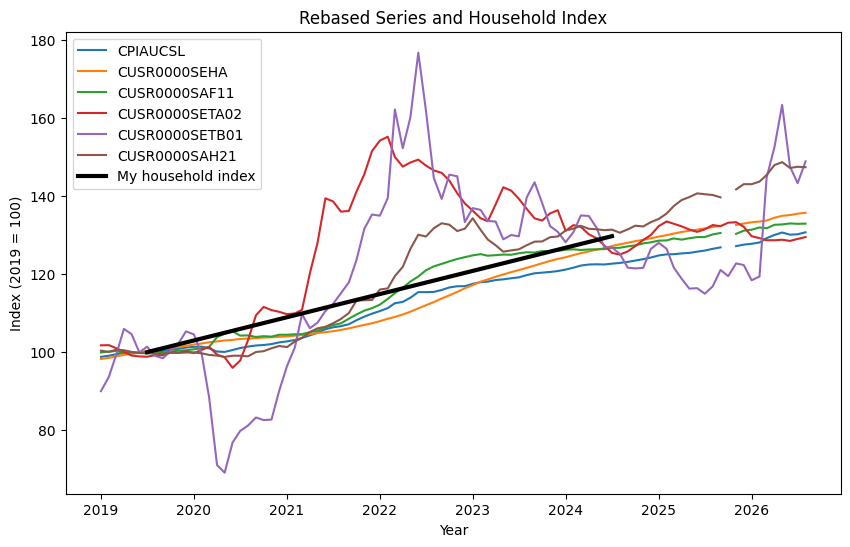

In [22]:
# One chart: every rebased series, plus your household index
plot_data = rebased.loc["2019":]

fig, ax = plt.subplots(figsize=(10, 6))
for series_id in plot_data.columns:
    ax.plot(plot_data.index, plot_data[series_id], label=series_id)

household_index = laspeyres(household_basket, "Price_2019", "Price_2024")
ax.plot(pd.to_datetime(["2019-07-01", "2024-07-01"]), [100, household_index],
        color="black", linewidth=3, label="My household index")

ax.set_xlabel("Year")
ax.set_ylabel("Index (2019 = 100)")
ax.set_title("Rebased Series and Household Index")
ax.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [18]:
# First observation, last observation, frequency and missing months, for every series
audit_rows = []
for series_id in fred_basket.columns:
    s = fred_basket[series_id].dropna()
    grid = s.asfreq("MS")                      # one row per month, gaps become NaN
    missing = grid[grid.isna()].index
    audit_rows.append({
        "Series": series_id,
        "First": s.index.min().date(),
        "Last": s.index.max().date(),
        "Frequency": pd.infer_freq(s.index),
        "Missing months": len(missing),
    })
    if len(missing) > 0:
        print(f"{series_id} missing:", [d.strftime("%Y-%m") for d in missing])

audit = pd.DataFrame(audit_rows)
audit

CPIAUCSL missing: ['2025-10']
CUSR0000SEHA missing: ['2025-10']
CUSR0000SAF11 missing: ['2025-10']
CUSR0000SAH21 missing: ['2025-10']


,Series,First,Last,Frequency,Missing months
0,CPIAUCSL,1947-01-01,2026-08-01,None,1
1,CUSR0000SEHA,1981-01-01,2026-08-01,None,1
2,CUSR0000SAF11,1952-01-01,2026-08-01,None,1
3,CUSR0000SETA02,1953-01-01,2026-08-01,MS,0
4,CUSR0000SETB01,1967-01-01,2026-08-01,MS,0
5,CUSR0000SAH21,1967-01-01,2026-08-01,None,1


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
| | | | | |

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [19]:
# Start dates side by side, and the common sample
starts = fred_basket.apply(lambda s: s.first_valid_index())
ends = fred_basket.apply(lambda s: s.last_valid_index())
print(pd.DataFrame({"Start": starts.dt.date, "End": ends.dt.date}))

common_start = starts.max()
common_end = ends.min()
common = fred_basket.loc[common_start:common_end]

longest = starts.idxmin()
discarded = (fred_basket[longest].dropna().index < common_start).sum()

print(f"\nCommon sample starts: {common_start.date()} (set by {starts.idxmax()})")
print(f"Common sample length: {len(common)} months")
print(f"Longest series: {longest}, discards {discarded} months")

                     Start         End
CPIAUCSL        1947-01-01  2026-08-01
CUSR0000SEHA    1981-01-01  2026-08-01
CUSR0000SAF11   1952-01-01  2026-08-01
CUSR0000SETA02  1953-01-01  2026-08-01
CUSR0000SETB01  1967-01-01  2026-08-01
CUSR0000SAH21   1967-01-01  2026-08-01

Common sample starts: 1981-01-01 (set by CUSR0000SEHA)
Common sample length: 548 months
Longest series: CPIAUCSL, discards 408 months


In [20]:
# Headline comparison: full history vs common sample
def annual_growth(s):
    """Average annual % growth from first to last observation."""
    s = s.dropna()
    years = (s.index[-1] - s.index[0]).days / 365.25
    return ((s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1) * 100

full_history = fred_basket.apply(annual_growth)
common_sample = common.apply(annual_growth)

comparison = pd.DataFrame({
    "Full history (%/yr)": full_history,
    "Common sample (%/yr)": common_sample,
})
comparison["Difference"] = comparison["Common sample (%/yr)"] - comparison["Full history (%/yr)"]
comparison.round(2)

,Full history (%/yr),Common sample (%/yr),Difference
CPIAUCSL,3.51,2.99,-0.52
CUSR0000SEHA,3.73,3.73,0.00
CUSR0000SAF11,3.18,2.75,-0.43
CUSR0000SETA02,2.53,2.10,-0.44
CUSR0000SETB01,4.42,2.68,-1.74
CUSR0000SAH21,4.51,2.88,-1.63


**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample assumes that comparing the same time period is fairest and representative, but fewer observations can make growth rates more sensitive to unusual events like the 2021–22 inflation spike. Not restricting assumes each series’ full history is informative, but different start dates may reflect different economic conditions and distort comparisons. The Difference column shows which series are most affected by this choice; larger differences mean conclusions depend more on the sample window selected.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

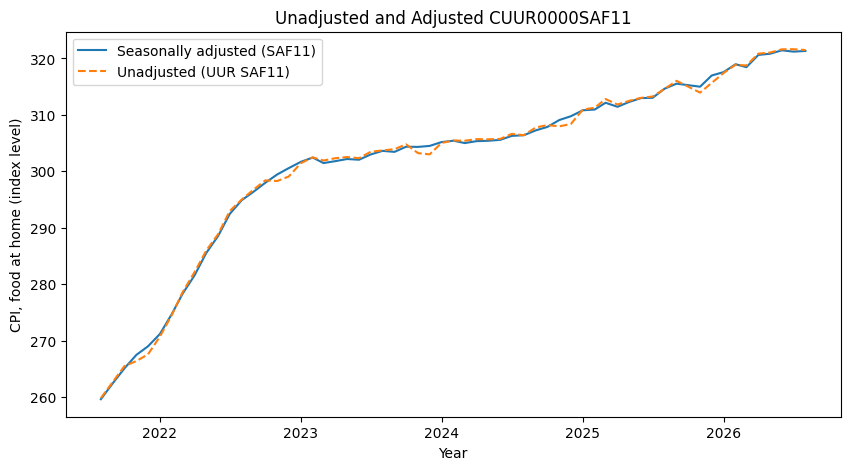

count    60.00
mean     -0.01
std       0.61
min      -1.50
25%      -0.10
50%       0.22
75%       0.40
max       0.66
dtype: float64


In [23]:
# Seasonally adjusted vs unadjusted, last five years
unadjusted = load_fred("CUUR0000SAF11")
adjusted = fred_basket["CUSR0000SAF11"].dropna()

pair = pd.DataFrame({"Seasonally adjusted": adjusted,
                     "Unadjusted": unadjusted}).dropna()
last5 = pair.loc[pair.index.max() - pd.DateOffset(years=5):]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(last5.index, last5["Seasonally adjusted"], label="Seasonally adjusted (SAF11)")
ax.plot(last5.index, last5["Unadjusted"], label="Unadjusted (UUR SAF11)", linestyle="--")
ax.set_xlabel("Year")
ax.set_ylabel("CPI, food at home (index level)")
ax.set_title("Unadjusted and Adjusted Food at Home (CUUR0000SAF11)")
ax.legend()
plt.show()

gap = (last5["Unadjusted"] - last5["Seasonally adjusted"])
print(gap.describe().round(2))

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines represents the seasonal factor, not random noise or a different measurement. It averages close to zero (-0.01) but fluctuates monthly, with a standard deviation of 0.61 index points. The seasonally adjusted series is best for comparing inflation across months because it removes predictable seasonal patterns. However, it is an estimate that BLS may revise, while the unadjusted series reflects actual prices paid. Since the brief compares full years (2019 and 2024), seasonality matters less for long-term comparisons than for month-to-month changes.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Dining out & other    7.66
Shopping              3.55
Car payments          2.62
Utilities             2.23
Gasoline              1.28
Rent                  0.59
Groceries             0.57
dtype: float64

Index change from +1 point of weight:
Dining out & other   -0.153
Utilities            -0.045
Gasoline             -0.026
Groceries            -0.011
Rent                  0.012
Car payments          0.052
Shopping              0.071
dtype: float64


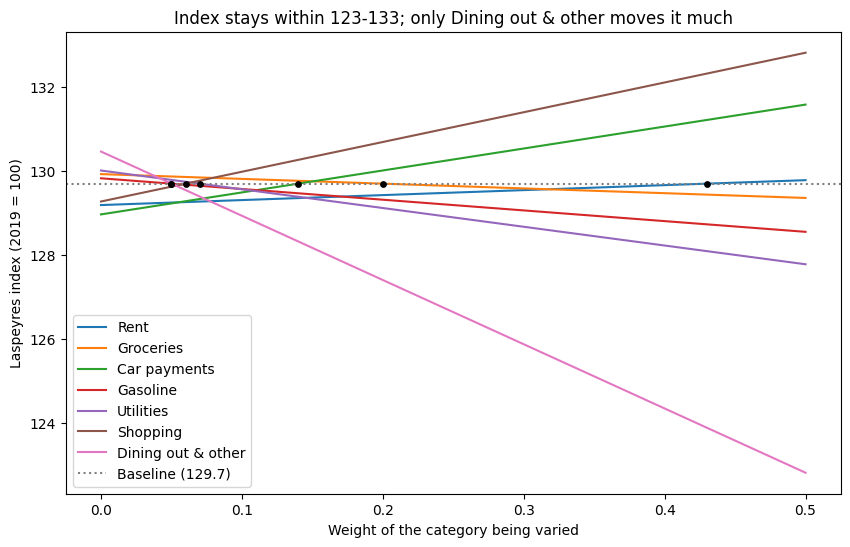

In [24]:
# Paste the AI's code here, run it, and correct it where it is wrong
# Reuse household_basket (keys: Item, Price_2019, Price_2024, weight)
names = [item["Item"] for item in household_basket]
base_w = np.array([item["weight"] for item in household_basket])
ratios = np.array([item["Price_2024"] / item["Price_2019"] for item in household_basket])
base_index = (base_w * ratios).sum() * 100           # CHANGE 1: baseline for reference

sweep = np.linspace(0, 0.5, 51)   # weights to try for the category being varied

def index_with_weight(i, w):
    """Laspeyres index (2019 = 100) when category i has weight w and the
    other categories keep their relative proportions."""
    # MECHANISM CHECK: renormalising is necessary because Laspeyres weights
    # are spending shares and must sum to 1. If we changed one weight and
    # left the rest alone, the weights would sum to more or less than 1 and
    # the "index" would drift just because total weight changed, not
    # because of the category we are testing. Scaling the others by
    # (1 - w) / (1 - original weight of i) keeps their ratios to each other
    # fixed and makes the total exactly 1.
    new_w = base_w * (1 - w) / (1 - base_w[i])
    new_w[i] = w
    assert abs(new_w.sum() - 1) < 1e-9, "weights must sum to 1"   # CHANGE 2: built-in check
    return (new_w * ratios).sum() * 100

# One row per weight, one column per category
results = pd.DataFrame(
    {names[i]: [index_with_weight(i, w) for w in sweep] for i in range(len(names))},
    index=sweep,
)
results.index.name = "weight"

# Swing = highest index minus lowest index across the sweep
swing = (results.max() - results.min()).sort_values(ascending=False)
print(swing.round(2))

# CHANGE 3: realistic sensitivity, i.e. index change from adding 1 point of weight
# to each category at its ACTUAL weight (the 0-0.5 swing includes unrealistic weights)
slope = pd.Series({names[i]: index_with_weight(i, base_w[i] + 0.01) - base_index
                   for i in range(len(names))})
print("\nIndex change from +1 point of weight:")
print(slope.round(3).sort_values())

fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(names):
    ax.plot(results.index, results[name], label=name)
    ax.scatter(base_w[i], index_with_weight(i, base_w[i]), color="black", zorder=3, s=15)

ax.axhline(base_index, color="gray", linestyle=":", label=f"Baseline ({base_index:.1f})")   # CHANGE 4

# MECHANISM CHECK: a steep line means the headline number depends heavily on
# our weight guess for that category. If the index were highly sensitive to
# one category, a small error in estimating that spending share would
# change the conclusion, so the client should be told the result is only
# as reliable as that one weight.
ax.set_xlabel("Weight of the category being varied")
ax.set_ylabel("Laspeyres index (2019 = 100)")
# CHANGE 5: title states the range as a finding
ax.set_title(f"Index stays within {results.min().min():.0f}-{results.max().max():.0f}; "
             f"only {swing.index[0]} moves it much")
ax.legend()
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

One thing is the category count. The prompt said “six categories,” but the basket has seven. The code handled it because it uses len(household_basket). Another is unverified numbers. The model’s swing table was a hand calculation. Running the code gave Dining 7.66, Shopping 3.55, Car payments 2.62, Utilities 2.23, Gasoline 1.28, Rent 0.59, Groceries 0.57, so the ranking held up.


### AI Transcript

**Model:** Claude Sonnet 5.5 &nbsp; **Date:** 10/9/2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

Dining out & other    7.66
Shopping              3.55
Car payments          2.62
Utilities             2.23
Gasoline              1.28
Rent                  0.59
Groceries             0.57
dtype: float64


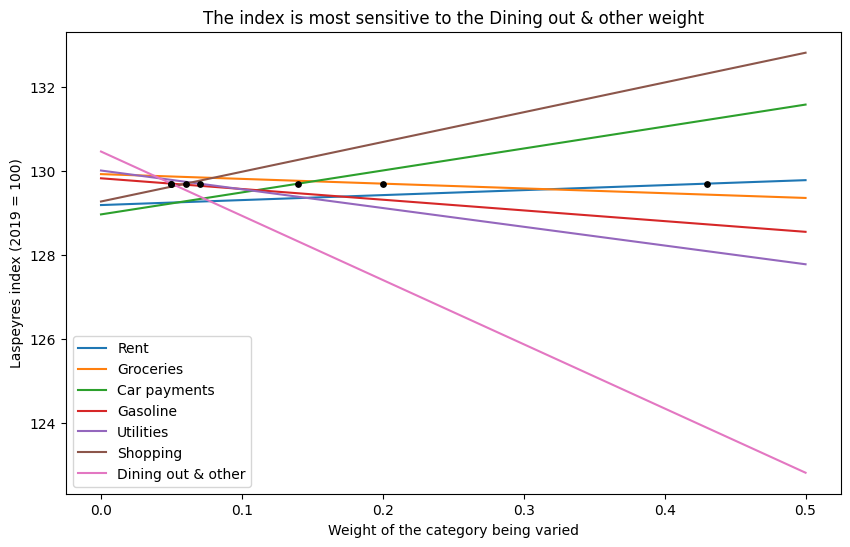

In [25]:
# Reuse household_basket (keys: Item, Price_2019, Price_2024, weight)
names = [item["Item"] for item in household_basket]
base_w = np.array([item["weight"] for item in household_basket])
ratios = np.array([item["Price_2024"] / item["Price_2019"] for item in household_basket])

sweep = np.linspace(0, 0.5, 51)   # weights to try for the category being varied

def index_with_weight(i, w):
    """Laspeyres index (2019 = 100) when category i has weight w and the
    other categories keep their relative proportions."""
    # MECHANISM CHECK: renormalising is necessary because Laspeyres weights
    # are spending shares and must sum to 1. If we changed one weight and
    # left the rest alone, the weights would sum to more or less than 1 and
    # the "index" would drift just because total weight changed, not
    # because of the category we are testing. Scaling the others by
    # (1 - w) / (1 - original weight of i) keeps their ratios to each other
    # fixed and makes the total exactly 1.
    new_w = base_w * (1 - w) / (1 - base_w[i])
    new_w[i] = w
    return (new_w * ratios).sum() * 100

# One row per weight, one column per category
results = pd.DataFrame(
    {names[i]: [index_with_weight(i, w) for w in sweep] for i in range(len(names))},
    index=sweep,
)
results.index.name = "weight"

# Swing = highest index minus lowest index across the sweep
swing = (results.max() - results.min()).sort_values(ascending=False)
print(swing.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(names):
    ax.plot(results.index, results[name], label=name)
    # dot marks where the household actually sits
    ax.scatter(base_w[i], index_with_weight(i, base_w[i]), color="black", zorder=3, s=15)

# MECHANISM CHECK: a steep line means the headline number depends heavily on
# our weight guess for that category. If the index were highly sensitive to
# one category, a small error in estimating that spending share would
# change the conclusion, so the client should be told the result is only
# as reliable as that one weight.
ax.set_xlabel("Weight of the category being varied")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"The index is most sensitive to the {swing.index[0]} weight")
ax.legend()
plt.show()

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

This household’s cost of living rose 29.7% from 2019 to 2024, reaching an index of 129.7. Rent (43%), groceries (20%), and car payments (14%) account for the largest spending shares, based on the household’s 2019 budget. The weighted increase exceeds the simple average of 28.2% because major spending categories, particularly rent and groceries, experienced relatively large price increases.

Compared with the official CPI-U increase of approximately 22%, our household experienced about 7 percentage points more inflation than the national average. The estimate is relatively stable under different spending assumptions: varying each category’s share between 0% and 50%, while adjusting the remaining shares proportionally, produces an index between 122.8 and 132.8. Dining out has the greatest influence because its prices rose only about 15%, considerably less than most other categories. Rent’s weight has little effect because its price increase is close to the overall basket average.

Confidence is moderate to high that household inflation was approximately 28%–31%. However, the 2019 and 2024 prices are estimates rather than directly measured data, and national price indexes may not accurately reflect the household’s actual housing, transportation, and utility costs. Additionally, if the household spends substantially more on dining out than assumed, its actual inflation rate would likely be lower. Therefore, the 29.7% estimate is a useful approximation, not an exact measurement.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub